In [11]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
conn = sqlite3.connect('../db/bluestock_mf.db')
cursor = conn.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
print("Tables in database:", cursor.fetchall())

Tables in database: []


In [16]:
sns.set_theme(style="whitegrid")

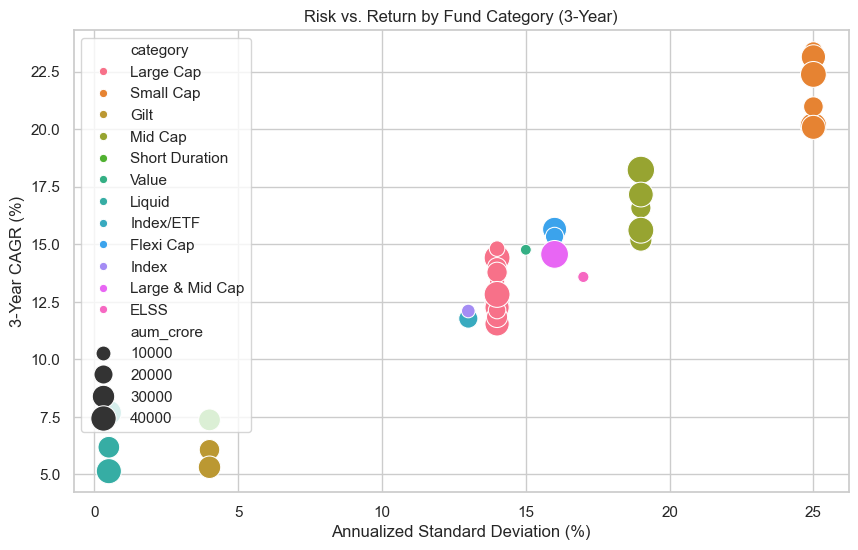

Chart saved successfully to ../reports/risk_return_scatter.png


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('../reports', exist_ok=True)

df_perf = pd.read_csv('../data/raw/07_scheme_performance.csv')


plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_perf, 
    x='std_dev_ann_pct', 
    y='return_3yr_pct', 
    hue='category', 
    size='aum_crore', 
    sizes=(50, 400)
)
plt.title("Risk vs. Return by Fund Category (3-Year)")
plt.xlabel("Annualized Standard Deviation (%)")
plt.ylabel("3-Year CAGR (%)")

plt.savefig('../reports/risk_return_scatter.png', bbox_inches='tight')
plt.show()

print("Chart saved successfully to ../reports/risk_return_scatter.png")

C:\Users\tanay\AppData\Local\Temp\ipykernel_7112\1752010531.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_txn, x='transaction_type', palette="viridis")


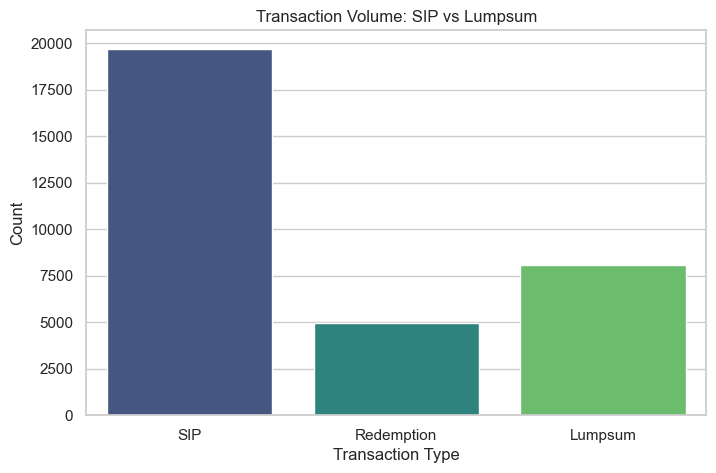

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_txn = pd.read_csv('../data/raw/08_investor_transactions.csv')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_txn, x='transaction_type', palette="viridis")
plt.title("Transaction Volume: SIP vs Lumpsum")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

C:\Users\tanay\AppData\Local\Temp\ipykernel_7112\3947139215.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=state_vol.values, y=state_vol.index, palette="mako")


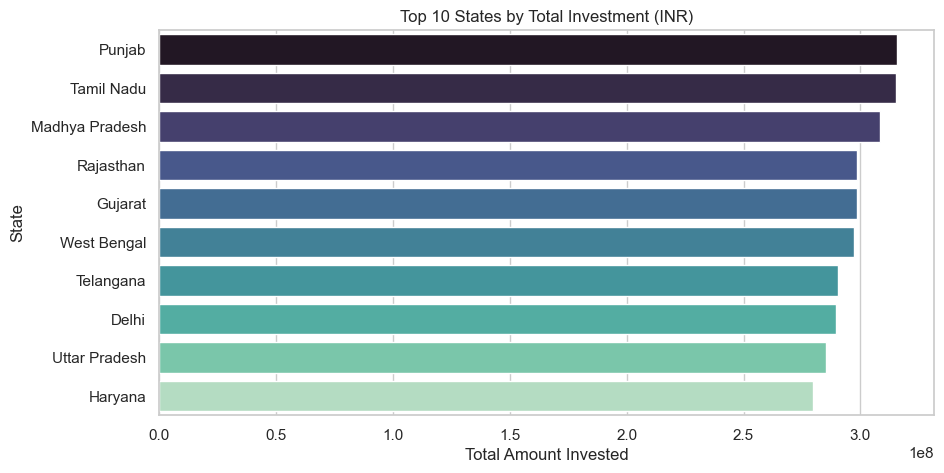

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_txn = pd.read_csv('../data/raw/08_investor_transactions.csv')

plt.figure(figsize=(10, 5))
state_vol = df_txn.groupby('state')['amount_inr'].sum().sort_values(ascending=False).head(10)

sns.barplot(x=state_vol.values, y=state_vol.index, palette="mako")

plt.title("Top 10 States by Total Investment (INR)")
plt.xlabel("Total Amount Invested")
plt.ylabel("State")
plt.show()

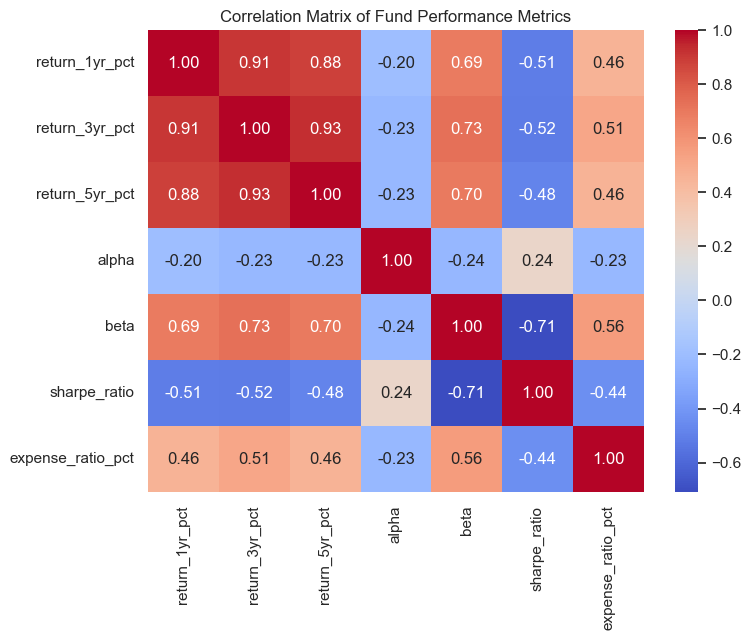

In [23]:
plt.figure(figsize=(8, 6))
cols = ['return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'expense_ratio_pct']
sns.heatmap(df_perf[cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Fund Performance Metrics")
plt.show()

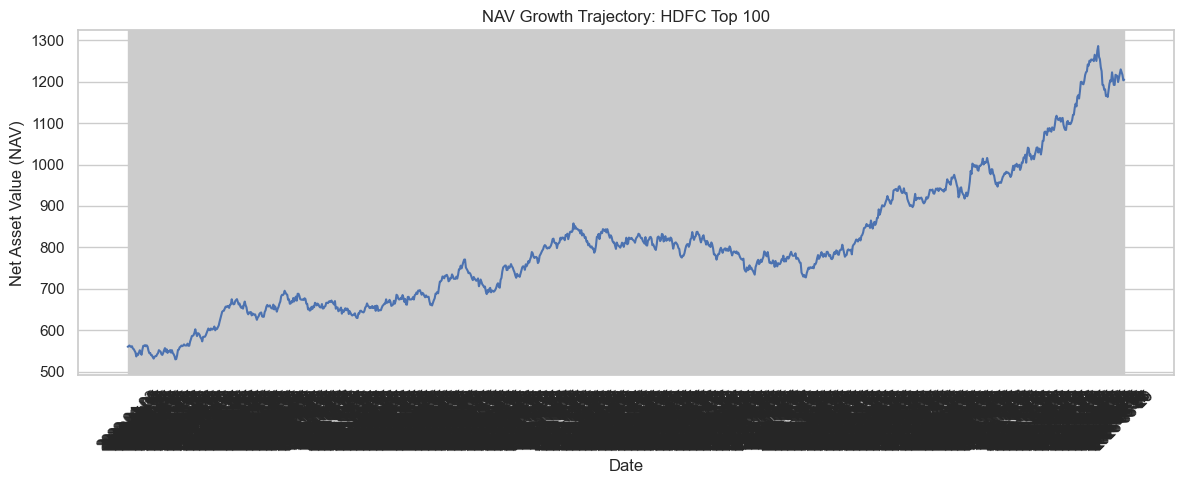

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_nav = pd.read_csv('../data/raw/02_nav_history.csv')

df_nav['amfi_code'] = df_nav['amfi_code'].astype(str)
top_fund_nav = df_nav[df_nav['amfi_code'] == '125497']

plt.figure(figsize=(12, 5))

sns.lineplot(data=top_fund_nav, x='date', y='nav')

plt.title("NAV Growth Trajectory: HDFC Top 100")
plt.xlabel("Date")
plt.ylabel("Net Asset Value (NAV)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()